# Лабораторная работа №4 — байесовская сеть

**Цель:** построить сеть зависимостей и исследовать, как дополнительные сведения меняют вероятности. Данные: [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/reference/penguins.html); задание — [ТЗ](materials/lab04.pdf). Одна строка описывает пингвина: вид, остров, пол, размеры тела и год наблюдения. Оценки относятся к этой выборке.

In [1]:
from itertools import product
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import FancyArrowPatch

DATA_PATH = Path('data/penguins.csv')
ALPHA = 0.5  # псевдосчёт на каждое состояние в каждой колонке CPT
BILL_BOUNDARY_MM = 45
FLIPPER_BOUNDARY_MM = 200
NODES = ['island', 'sex', 'species', 'bill_length_group', 'flipper_length_group']
STATES = {
    'island': ['Biscoe', 'Dream', 'Torgersen'],
    'sex': ['female', 'male'],
    'species': ['Adelie', 'Chinstrap', 'Gentoo'],
    'bill_length_group': ['short', 'long'],
    'flipper_length_group': ['short', 'long'],
}
print('Версии: pandas', pd.__version__, '| numpy', np.__version__,
      '| matplotlib', matplotlib.__version__)

Версии: pandas 3.1.0 | numpy 2.5.4 | matplotlib 3.11.2


## 1. Данные и подготовка

В исходных данных 344 строки: вид, остров, пол, длина и глубина клюва, длина плавника, масса и год. Для сети выбираем вид, остров, пол и две длины: так таблицы вероятностей остаются достаточно компактными.

In [2]:
raw = pd.read_csv(DATA_PATH, na_values='NA')
assert raw.shape[1] == 8
display(raw.head())
summary = pd.DataFrame({
    'тип': raw.dtypes.astype(str),
    'пропуски': raw.isna().sum(),
    'уникальных': raw.nunique(dropna=True),
})
display(summary)
for name in ('species', 'island', 'sex'):
    print(f'{name}:', raw[name].value_counts(dropna=False).to_dict())
print('Полных повторов строк:', raw.duplicated().sum())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


,тип,пропуски,уникальных
species,str,0,3
island,str,0,3
bill_length_mm,float64,2,164
bill_depth_mm,float64,2,80
flipper_length_mm,float64,2,55
body_mass_g,float64,2,94
sex,str,11,2
year,int64,0,3


species: {'Adelie': 152, 'Gentoo': 124, 'Chinstrap': 68}
island: {'Biscoe': 168, 'Dream': 124, 'Torgersen': 52}
sex: {'male': 168, 'female': 165, nan: 11}
Полных повторов строк: 0


**Вывод.** В поле `sex` 11 пропусков, в каждом измерении — по 2; полных дублей нет. Идентификатора птицы нет, поэтому повторные наблюдения одной особи полностью исключить нельзя.

Удаляем строки с пропусками выбранных признаков. Длину клюва делим на `< 45` и `≥ 45` мм, плавника — на `< 200` и `≥ 200` мм. Пороги заданы до расчётов; две категории делают вероятности понятными и сокращают число параметров.

In [3]:
selected = ['island', 'sex', 'species', 'bill_length_mm', 'flipper_length_mm']
complete = raw[selected].dropna().copy()
complete['bill_length_group'] = np.where(
    complete['bill_length_mm'] < BILL_BOUNDARY_MM, 'short', 'long'
)
complete['flipper_length_group'] = np.where(
    complete['flipper_length_mm'] < FLIPPER_BOUNDARY_MM, 'short', 'long'
)
data = complete[NODES].copy()
assert len(data) == 333
assert all(set(data[c]) == set(STATES[c]) for c in NODES)
print(f'Полных строк: {len(data)} из {len(raw)}; исключено: {len(raw) - len(data)}')
display(pd.DataFrame({
    'переменная': NODES,
    'число состояний': [len(STATES[n]) for n in NODES],
    'частоты состояний': [data[n].value_counts().to_dict() for n in NODES],
}))
print('Число строк для каждой комбинации вида и пола:')
display(data.groupby(['species', 'sex']).size().unstack(fill_value=0))
print('Число строк для каждой комбинации острова и вида:')
display(data.groupby(['island', 'species']).size().unstack(fill_value=0))

Полных строк: 333 из 344; исключено: 11


,переменная,число состояний,частоты состояний
0,island,3,"{'Biscoe': 163, 'Dream': 123, 'Torgersen': 47}"
1,sex,2,"{'male': 168, 'female': 165}"
2,species,3,"{'Adelie': 146, 'Gentoo': 119, 'Chinstrap': 68}"
3,bill_length_group,2,"{'short': 169, 'long': 164}"
4,flipper_length_group,2,"{'short': 185, 'long': 148}"


Число строк для каждой комбинации вида и пола:


sex,female,male
species,,
Adelie,73,73
Chinstrap,34,34
Gentoo,58,61


Число строк для каждой комбинации острова и вида:


species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,44,0,119
Dream,55,68,0
Torgersen,47,0,0


**Вывод.** Осталось 333 наблюдения. Некоторые сочетания вида и острова отсутствуют, а исключение 11 строк может повлиять на результат.

## 2. Вопросы и структура сети

1. Как меняется вероятность вида Gentoo, если плавник длинный?
2. Как меняется вероятность Chinstrap, если известны остров Dream и длинный клюв?
3. Как меняется вероятность длинного плавника, если известны вид Chinstrap и мужской пол?

Предлагаем рёбра `island → species`, а также рёбра от `species` и `sex` к обеим длинам. Остров связан с составом наблюдаемых видов; вид и пол могут быть связаны с размерами. Стрелки к измерениям отражают выбранное описание данных; `island → species` задаёт распределение вида по острову. Направления сами по себе не доказывают причинность. Проверяем, что граф ацикличен.

Сеть предполагает независимость двух измерений при известных виде и поле; прямой связи острова с размерами нет. Факторизация: `P(I,S,V,B,F) = P(I) P(S) P(V|I) P(B|V,S) P(F|V,S)`, где `I` — остров, `S` — пол, `V` — вид, `B` — клюв, `F` — плавник.

DAG: топологический порядок проверен; рёбра: [('island', 'species'), ('species', 'bill_length_group'), ('sex', 'bill_length_group'), ('species', 'flipper_length_group'), ('sex', 'flipper_length_group')]


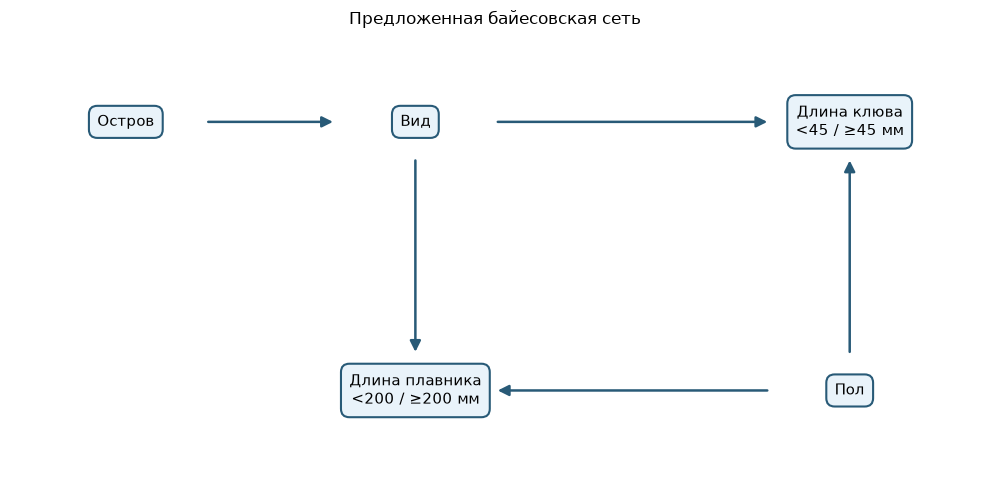

In [4]:
PARENTS = {
    'island': [],
    'sex': [],
    'species': ['island'],
    'bill_length_group': ['species', 'sex'],
    'flipper_length_group': ['species', 'sex'],
}
EDGES = [(parent, child) for child, parents in PARENTS.items() for parent in parents]
node_order = {node: index for index, node in enumerate(NODES)}
assert len(EDGES) == 5
assert all(node_order[parent] < node_order[child] for parent, child in EDGES)
print('DAG: топологический порядок проверен; рёбра:', EDGES)

positions = {
    'island': (-2, 1.5), 'species': (0, 1.5),
    'bill_length_group': (3, 1.5), 'sex': (3, -1.5),
    'flipper_length_group': (0, -1.5),
}
labels = {
    'island': 'Остров', 'sex': 'Пол', 'species': 'Вид',
    'bill_length_group': 'Длина клюва\n<45 / ≥45 мм',
    'flipper_length_group': 'Длина плавника\n<200 / ≥200 мм',
}
fig, ax = plt.subplots(figsize=(10, 5))
for node, (x, y) in positions.items():
    ax.text(x, y, labels[node], ha='center', va='center', fontsize=11,
            bbox=dict(boxstyle='round,pad=0.55', fc='#e9f3fa', ec='#285a77', lw=1.5))
for parent, child in EDGES:
    start = np.array(positions[parent], dtype=float)
    end = np.array(positions[child], dtype=float)
    direction = (end - start) / np.linalg.norm(end - start)
    offset = 0.40 if start[0] == end[0] else 0.55
    start += offset * direction
    end -= offset * direction
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle='-|>', mutation_scale=16,
                                 lw=1.8, color='#285a77'))
ax.set(xlim=(-2.8, 3.9), ylim=(-2.5, 2.5), title='Предложенная байесовская сеть')
ax.axis('off')
plt.tight_layout()
plt.show()

## 3. Условные вероятности

Для каждого состояния и сочетания родителей добавляем 0,5 псевдонаблюдения: $P(X=x|Pa=u)=(n(x,u)+0.5)/(n(u)+0.5|X|)$. Сглаживание уменьшает уверенность в оценках по редким и ненаблюдавшимся сочетаниям. `n_parent` — размер группы, `n_state` — число наблюдений состояния; сравним оценки с частотами тех же данных.

In [5]:
def estimate_cpds(frame, parent_map, alpha=ALPHA):
    cpds = {}
    for node in NODES:
        parents = parent_map[node]
        configs = list(product(*(STATES[p] for p in parents))) if parents else [()]
        rows = []
        for config in configs:
            mask = pd.Series(True, index=frame.index)
            for parent, value in zip(parents, config):
                mask &= frame[parent].eq(value)
            counts = frame.loc[mask, node].value_counts().reindex(STATES[node], fill_value=0)
            total = int(counts.sum())
            for state in STATES[node]:
                rows.append({**dict(zip(parents, config)), node: state,
                             'n_parent': total, 'n_state': int(counts[state]),
                             'probability': (counts[state] + alpha) /
                                            (total + alpha * len(STATES[node]))})
        cpds[node] = pd.DataFrame(rows)
    return cpds


cpds = estimate_cpds(data, PARENTS)
for node, table in cpds.items():
    parents = PARENTS[node]
    sums = table.groupby(parents)['probability'].sum() if parents else [table['probability'].sum()]
    assert np.allclose(sums, 1.0)
    assert table['probability'].between(0, 1).all()
print('Все условные распределения нормированы и лежат в [0, 1].')
for node, conditions in [
    ('species', {'island': 'Dream'}),
    ('bill_length_group', {'species': 'Chinstrap', 'sex': 'male'}),
    ('flipper_length_group', {'species': 'Chinstrap', 'sex': 'male'}),
]:
    table = cpds[node]
    for parent, value in conditions.items():
        table = table[table[parent].eq(value)]
    table = table.copy()
    table['empirical'] = table['n_state'] / table['n_parent']
    print(f'P({node} | {conditions})')
    display(table.round({'probability': 3, 'empirical': 3}))

Все условные распределения нормированы и лежат в [0, 1].
P(species | {'island': 'Dream'})


,island,species,n_parent,n_state,probability,empirical
3,Dream,Adelie,123,55,0.446,0.447
4,Dream,Chinstrap,123,68,0.550,0.553
5,Dream,Gentoo,123,0,0.004,0.000


P(bill_length_group | {'species': 'Chinstrap', 'sex': 'male'})


,species,sex,bill_length_group,n_parent,n_state,probability,empirical
6,Chinstrap,male,short,34,0,0.014,0.0
7,Chinstrap,male,long,34,34,0.986,1.0


P(flipper_length_group | {'species': 'Chinstrap', 'sex': 'male'})


,species,sex,flipper_length_group,n_parent,n_state,probability,empirical
6,Chinstrap,male,short,34,16,0.471,0.471
7,Chinstrap,male,long,34,18,0.529,0.529


**Вывод.** На Dream среди 123 полных записей 68 Chinstrap, 55 Adelie и ни одного Gentoo. Сглаживание даёт Gentoo вероятность 0,004, хотя его не наблюдали. У всех 34 самцов Chinstrap клюв длинный, но сглаженная оценка равна 0,986. Доля длинных плавников в этой группе — 18/34 ≈ 0,529, и модель даёт близкое значение. Это проверка на тех же данных; пропуски и малые группы ограничивают выводы.

## 4. Вероятностные запросы

Совместное распределение вычисляем перемножением CPT для всех 72 сочетаний состояний. Чтобы получить условную вероятность, суммируем подходящие сочетания и нормируем результат.

In [6]:
def make_joint(cpd_tables, parent_map):
    combinations = list(product(*(STATES[node] for node in NODES)))
    joint = pd.DataFrame(combinations, columns=NODES)
    joint['probability'] = 1.0
    for node in NODES:
        keys = parent_map[node] + [node]
        factor = cpd_tables[node][keys + ['probability']].rename(
            columns={'probability': f'factor_{node}'})
        joint = joint.merge(factor, on=keys, how='left', validate='many_to_one')
        assert joint[f'factor_{node}'].notna().all()
        joint['probability'] *= joint[f'factor_{node}']
        joint = joint.drop(columns=f'factor_{node}')
    assert np.isclose(joint['probability'].sum(), 1.0)
    return joint


def posterior(joint, target, evidence=None):
    evidence = evidence or {}
    selected = joint
    for variable, value in evidence.items():
        assert variable != target and value in STATES[variable]
        selected = selected[selected[variable].eq(value)]
    evidence_probability = selected['probability'].sum()
    assert evidence_probability > 0
    result = selected.groupby(target)['probability'].sum().reindex(STATES[target], fill_value=0)
    result = result / evidence_probability
    assert np.isclose(result.sum(), 1.0)
    return result


def scenario_table(joint, target, scenarios):
    return pd.DataFrame({label: posterior(joint, target, evidence)
                         for label, evidence in scenarios}).T


joint = make_joint(cpds, PARENTS)
print('Совместная таблица:', len(joint), 'строк; сумма вероятностей:', joint.probability.sum())

Совместная таблица: 72 строк; сумма вероятностей: 1.0


In [7]:
q1 = scenario_table(joint, 'species', [
    ('Без сведений', {}),
    ('Плавник ≥ 200 мм', {'flipper_length_group': 'long'}),
])
q2 = scenario_table(joint, 'species', [
    ('Без сведений', {}),
    ('Остров Dream', {'island': 'Dream'}),
    ('Dream + клюв ≥ 45 мм', {'island': 'Dream', 'bill_length_group': 'long'}),
])
q3 = scenario_table(joint, 'flipper_length_group', [
    ('Без сведений', {}),
    ('Вид Chinstrap', {'species': 'Chinstrap'}),
    ('Chinstrap + самец', {'species': 'Chinstrap', 'sex': 'male'}),
])
for title, table, state in [
    ('Вопрос 1: вид при длинном плавнике', q1, 'Gentoo'),
    ('Вопрос 2: вид при острове и длине клюва', q2, 'Chinstrap'),
    ('Вопрос 3: плавник при виде и поле', q3, 'long'),
]:
    print(title)
    display(table.round(3))
    print(f'Изменение P({state}) от первого до последнего шага: '
          f'{100 * (table.iloc[-1][state] - table.iloc[0][state]):+.1f} п. п.')

Вопрос 1: вид при длинном плавнике


species,Adelie,Chinstrap,Gentoo
Без сведений,0.436,0.206,0.358
Плавник ≥ 200 мм,0.066,0.139,0.794


Изменение P(Gentoo) от первого до последнего шага: +43.6 п. п.
Вопрос 2: вид при острове и длине клюва


species,Adelie,Chinstrap,Gentoo
Без сведений,0.436,0.206,0.358
Остров Dream,0.446,0.550,0.004
Dream + клюв ≥ 45 мм,0.024,0.970,0.006


Изменение P(Chinstrap) от первого до последнего шага: +76.4 п. п.
Вопрос 3: плавник при виде и поле


flipper_length_group,short,long
Без сведений,0.553,0.447
Вид Chinstrap,0.698,0.302
Chinstrap + самец,0.471,0.529


Изменение P(long) от первого до последнего шага: +8.2 п. п.


**Вывод.** Длинный плавник повышает `P(Gentoo)` с **35,8% до 79,4%**. Остров Dream повышает `P(Chinstrap)` с **20,6% до 55,0%**, а вместе с длинным клювом — до **97,0%**. Для длинного плавника исходная вероятность **44,7%**; при виде Chinstrap — **30,2%**, при дополнительном условии `male` — **52,9%**.

## 5. Последовательное добавление сведений

Для вида последовательно учитываем остров Dream, длинный клюв и короткий плавник.

species,Adelie,Chinstrap,Gentoo
Нет сведений,0.436,0.206,0.358
Dream,0.446,0.550,0.004
Dream + клюв ≥45,0.024,0.970,0.006
Dream + клюв ≥45 + плавник <200,0.031,0.968,0.000


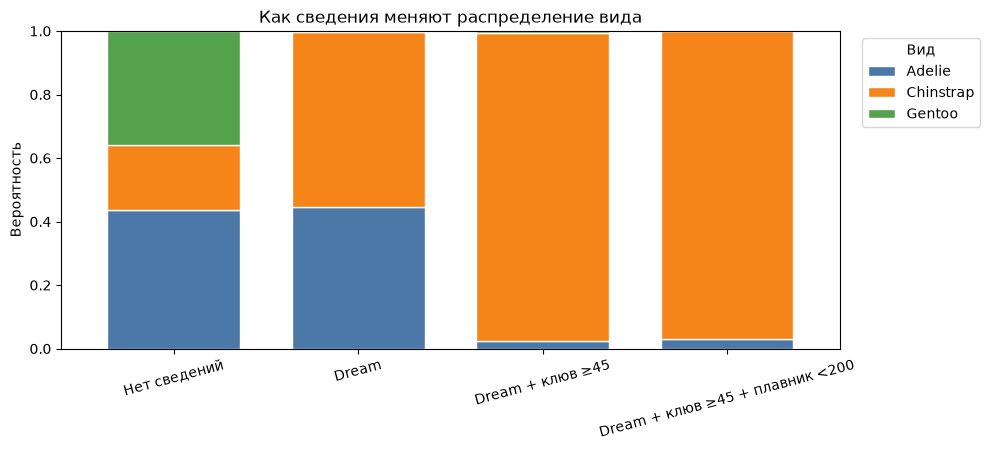

In [8]:
progressive = scenario_table(joint, 'species', [
    ('Нет сведений', {}),
    ('Dream', {'island': 'Dream'}),
    ('Dream + клюв ≥45', {'island': 'Dream', 'bill_length_group': 'long'}),
    ('Dream + клюв ≥45 + плавник <200',
     {'island': 'Dream', 'bill_length_group': 'long', 'flipper_length_group': 'short'}),
])
display(progressive.round(3))
assert np.allclose(progressive.sum(axis=1), 1.0)
ax = progressive.plot.bar(stacked=True, figsize=(10, 4.6),
                          color=['#4c78a8', '#f58518', '#54a24b'],
                          edgecolor='white', width=0.72)
ax.set(ylabel='Вероятность', xlabel='', ylim=(0, 1),
       title='Как сведения меняют распределение вида')
ax.legend(title='Вид', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

**Вывод.** `P(Chinstrap)` меняется от **20,6%** без сведений до **55,0%** при Dream, **97,0%** после добавления длинного клюва и **96,8%** после добавления короткого плавника. Сведения о размерах обновляют оценку вида через рёбра сети.

## 6. Удаление ребра

Удаляем `species → flipper_length_group`, заново оцениваем вероятности на тех же данных и повторяем первый запрос. Остальные рёбра и сглаживание сохраняем.

In [9]:
reduced_parents = {node: list(parents) for node, parents in PARENTS.items()}
reduced_parents['flipper_length_group'].remove('species')
reduced_edges = [(parent, child) for child, parents in reduced_parents.items()
                 for parent in parents]
assert len(reduced_edges) == len(EDGES) - 1
assert all(node_order[parent] < node_order[child] for parent, child in reduced_edges)
reduced_cpds = estimate_cpds(data, reduced_parents)
reduced_joint = make_joint(reduced_cpds, reduced_parents)
comparison = pd.concat({
    'Исходная сеть, без сведений': posterior(joint, 'species'),
    'Исходная сеть, длинный плавник': posterior(
        joint, 'species', {'flipper_length_group': 'long'}),
    'Без ребра, без сведений': posterior(reduced_joint, 'species'),
    'Без ребра, длинный плавник': posterior(
        reduced_joint, 'species', {'flipper_length_group': 'long'}),
}, axis=1).T
display(comparison.round(3))
print('В исходной сети Δ P(Gentoo):',
      round(comparison.iloc[1]['Gentoo'] - comparison.iloc[0]['Gentoo'], 3))
print('Без ребра Δ P(Gentoo):',
      round(comparison.iloc[3]['Gentoo'] - comparison.iloc[2]['Gentoo'], 3))


species,Adelie,Chinstrap,Gentoo
"Исходная сеть, без сведений",0.436,0.206,0.358
"Исходная сеть, длинный плавник",0.066,0.139,0.794
"Без ребра, без сведений",0.436,0.206,0.358
"Без ребра, длинный плавник",0.436,0.206,0.358


В исходной сети Δ P(Gentoo): 0.436
Без ребра Δ P(Gentoo): 0.0


**Вывод.** В исходной сети длинный плавник повышает `P(Gentoo)` с **35,8% до 79,4%**. После удаления ребра ответ остаётся **35,8%**: без дополнительных условий путь от плавника к виду закрыт. Вывод зависит от принятой структуры; одни наблюдения не позволяют надёжно установить направление связей.

## 7. Итог и ограничения

Сеть позволила оценить распределения вида и длины плавника при разных сведениях. На результаты влияют структура, пороги категорий, сглаживание и отсутствие некоторых сочетаний в выборке.

**Сеть не доказана как причинная модель:** стрелки отражают предположения о зависимостях, а вмешательства не проводились. Данные охватывают три острова и 333 полные строки; удаление пропусков может внести смещение. Сравнение CPT с частотами использует те же наблюдения и не показывает качество на новых данных.